Delio Fernando Palacios Viafara - 30000115782

# Clasificacion de Tumores Cerebrales con Transfer Learning
## Modelo base: EfficientNetB4 | Dataset: Brain Tumor MRI

---

**Dataset:** https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset

**Estructura original del dataset:**

```
brain-tumor-mri-dataset/
    Training/           5,600 imagenes (1,400 por clase)
        glioma/
        meningioma/
        notumor/
        pituitary/
    Testing/            1,600 imagenes (400 por clase)
        glioma/
        meningioma/
        notumor/
        pituitary/
```

**Splits utilizados:**
- Train: 80% de `Training/` -> 4,480 imagenes (1,120 por clase)
- Validacion: 20% de `Training/` -> 1,120 imagenes (280 por clase)
- Test: `Testing/` completo -> 1,600 imagenes (400 por clase)


---
## Configuracion del entorno en Google Colab

In [66]:
from google.colab import drive

drive.mount("/content/drive")
print("Google Drive montado en /content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado en /content/drive


---
## Descarga del dataset desde Kaggle 


In [ ]:
import os
from pathlib import Path

# Definición de rutas
DRIVE_PROJECT_DIR = Path("/content/brain_tumor_project")
DRIVE_DATA_DIR    = DRIVE_PROJECT_DIR / "data"
DRIVE_MODEL_DIR   = DRIVE_PROJECT_DIR / "models"

for d in [DRIVE_PROJECT_DIR, DRIVE_DATA_DIR, DRIVE_MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Proyecto en /content : {DRIVE_PROJECT_DIR}")
print(f"Datos                : {DRIVE_DATA_DIR}")
print(f"Modelos              : {DRIVE_MODEL_DIR}")

Proyecto en /content : /content/brain_tumor_project
Datos                : /content/brain_tumor_project/data
Modelos              : /content/brain_tumor_project/models


In [ ]:
# Credenciales Kaggle 
KAGGLE_FOLDER_PATH = "/content/drive/MyDrive/Kaggle"
os.environ["KAGGLE_CONFIG_DIR"] = KAGGLE_FOLDER_PATH

# Descargar y descomprimir dataset en /content 
DATASET_ZIP = "/content/brain-tumor-mri-dataset.zip"
DATASET_DIR = Path("/content")
TRAIN_DIR   = DATASET_DIR / "Training"
TEST_DIR    = DATASET_DIR / "Testing"

if TRAIN_DIR.exists() and TEST_DIR.exists():
    print("Dataset ya esta descomprimido. Se omite descarga y unzip.")
else:
    if not os.path.exists(DATASET_ZIP):
        print("Descargando dataset desde Kaggle...")
        !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content
    print("Descomprimiendo...")
    !unzip -n /content/brain-tumor-mri-dataset.zip -d /content

print(f"Training : {TRAIN_DIR}")
print(f"Testing  : {TEST_DIR}")

Dataset ya esta descomprimido. Se omite descarga y unzip.
Training : /content/Training
Testing  : /content/Testing


---
## Importaciones

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, TensorBoard
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc,accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import label_binarize

# Semilla global para reproducibilidad
SEED = 5
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


---
## Verificacion de la estructura del dataset y conteo de imagenes

El dataset tiene la siguiente estructura:
- **Total**: 7,200 imagenes
- **Training**: 5,600 imagenes, 1,400 por clase 
- **Testing**: 1,600 imagenes, 400 por clase 
- **Clases**: glioma, meningioma, notumor, pituitary


In [88]:
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Valores esperados segun la descripcion oficial del dataset
EXPECTED_CLASSES        = ["glioma", "meningioma", "notumor", "pituitary"]
EXPECTED_TRAIN_PER_CLASS = 1400
EXPECTED_TEST_PER_CLASS  = 400

def contar_imagenes_por_clase(directorio):
    """Devuelve un dict {nombre_clase: cantidad_imagenes}."""
    directorio = Path(directorio)
    conteo = {}
    for clase_dir in sorted(directorio.iterdir()):
        if not clase_dir.is_dir() or clase_dir.name.startswith("."):
            continue
        n = sum(
            1 for f in clase_dir.iterdir()
            if f.suffix.lower() in IMG_EXTENSIONS
        )
        conteo[clase_dir.name] = n
    return conteo

train_counts = contar_imagenes_por_clase(TRAIN_DIR)
test_counts  = contar_imagenes_por_clase(TEST_DIR)

# Mostrar conteos reales
print("Conteo real en disco:\n")
print(f"{'Clase':<15} {'Training':>10} {'Testing':>10} {'Total':>10}")
print("-" * 47)
for clase in sorted(train_counts):
    tr = train_counts.get(clase, 0)
    te = test_counts.get(clase, 0)
    print(f"{clase:<15} {tr:>10} {te:>10} {tr+te:>10}")
print("-" * 47)
total_tr = sum(train_counts.values())
total_te = sum(test_counts.values())
print(f"{'TOTAL':<15} {total_tr:>10} {total_te:>10} {total_tr+total_te:>10}")

# Validar contra valores esperados
print("\nValidacion de estructura:")
clases_encontradas = sorted(train_counts.keys())
assert clases_encontradas == EXPECTED_CLASSES, (
    f"Clases en disco {clases_encontradas} != esperadas {EXPECTED_CLASSES}"
)
print(f"  Clases encontradas      : {clases_encontradas}")

for clase in EXPECTED_CLASSES:
    assert train_counts[clase] == EXPECTED_TRAIN_PER_CLASS, (
        f"Training/{clase}: {train_counts[clase]} imagenes (esperadas {EXPECTED_TRAIN_PER_CLASS})"
    )
    assert test_counts[clase] == EXPECTED_TEST_PER_CLASS, (
        f"Testing/{clase}: {test_counts[clase]} imagenes (esperadas {EXPECTED_TEST_PER_CLASS})"
    )

print(f"  Training por clase    : {EXPECTED_TRAIN_PER_CLASS} ")
print(f"  Testing por clase     : {EXPECTED_TEST_PER_CLASS} ")

Conteo real en disco:

Clase             Training    Testing      Total
-----------------------------------------------
glioma                1400        400       1800
meningioma            1400        400       1800
notumor               1400        400       1800
pituitary             1400        400       1800
-----------------------------------------------
TOTAL                 5600       1600       7200

Validacion de estructura:
  Clases encontradas      : ['glioma', 'meningioma', 'notumor', 'pituitary']
  Training por clase    : 1400 
  Testing por clase     : 400 


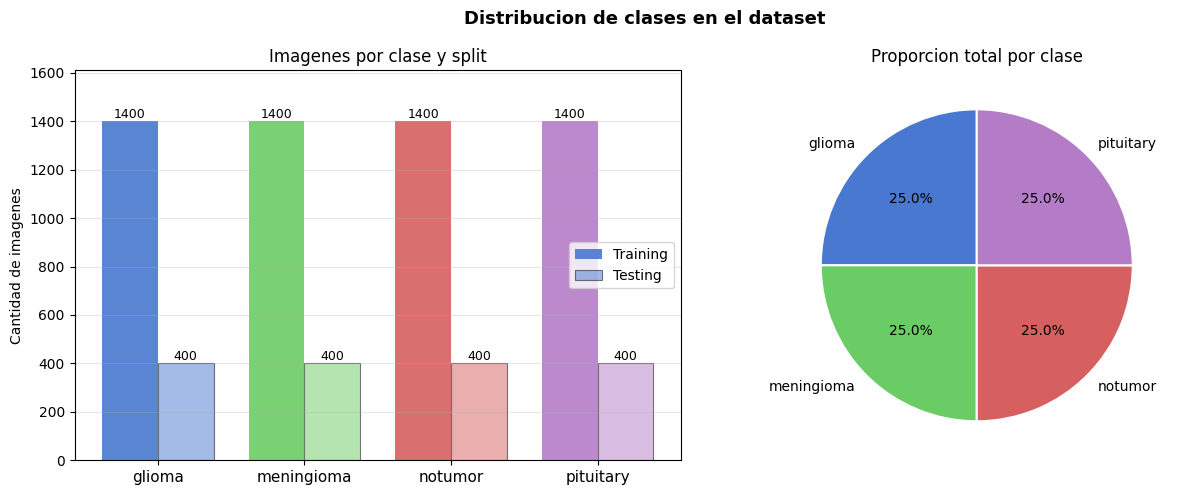

In [89]:
# Visualizar distribucion de clases
clases   = EXPECTED_CLASSES
tr_vals  = [train_counts[c] for c in clases]
te_vals  = [test_counts[c]  for c in clases]
COLORS   = ["#4878CF", "#6ACC65", "#D65F5F", "#B47CC7"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Distribucion de clases en el dataset", fontsize=13, fontweight="bold")

x = np.arange(len(clases))
w = 0.38
b1 = axes[0].bar(x - w/2, tr_vals, w, label="Training", color=COLORS, alpha=0.9)
b2 = axes[0].bar(x + w/2, te_vals, w, label="Testing",  color=COLORS, alpha=0.5, edgecolor="k", linewidth=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(clases, fontsize=11)
axes[0].set_ylabel("Cantidad de imagenes")
axes[0].set_title("Imagenes por clase y split")
axes[0].legend()
axes[0].set_ylim(0, max(tr_vals) * 1.15)
for bar, v in zip(b1, tr_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 15, str(v), ha="center", fontsize=9)
for bar, v in zip(b2, te_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 15, str(v), ha="center", fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

total_vals = [tr_vals[i] + te_vals[i] for i in range(len(clases))]
axes[1].pie(total_vals, labels=clases, autopct="%1.1f%%",
            colors=COLORS, startangle=90,
            wedgeprops=dict(edgecolor="white", linewidth=1.5))
axes[1].set_title("Proporcion total por clase")

plt.tight_layout()
plt.show()

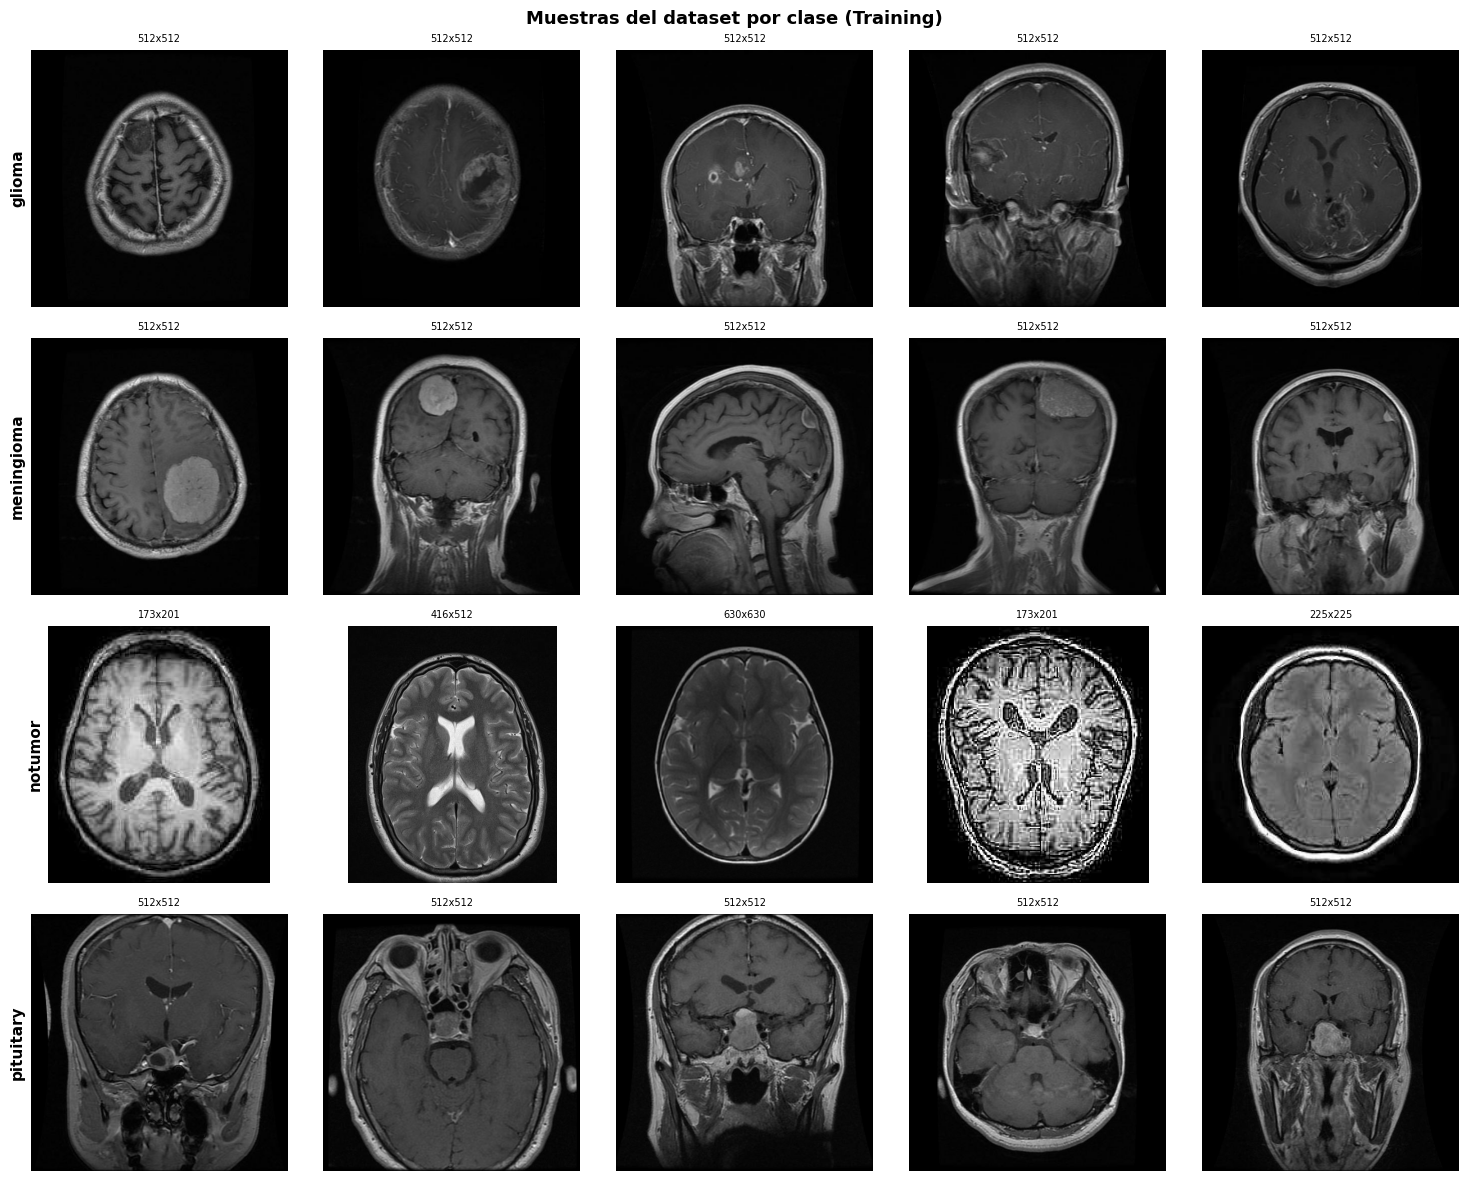

In [72]:
# Visualizar muestras del dataset por clase
N_SAMPLES = 5

fig, axes = plt.subplots(len(clases), N_SAMPLES, figsize=(N_SAMPLES * 3, len(clases) * 3))
fig.suptitle("Muestras del dataset por clase (Training)", fontsize=13, fontweight="bold")

for row, clase in enumerate(clases):
    ruta   = TRAIN_DIR / clase
    imgs   = [f for f in ruta.iterdir() if f.suffix.lower() in IMG_EXTENSIONS]
    muestra = random.sample(imgs, N_SAMPLES)

    for col, img_path in enumerate(muestra):
        img_bytes = tf.io.read_file(str(img_path))
        img = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.convert_image_dtype(img, tf.uint8)
        img_np = img.numpy()
        h, w = img_np.shape[:2]
        axes[row, col].imshow(img_np)
        axes[row, col].set_title(f"{w}x{h}", fontsize=7)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(clase, fontsize=11, fontweight="bold")
            axes[row, col].yaxis.set_label_position("left")
            axes[row, col].axis("on")
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            for spine in axes[row, col].spines.values():
                spine.set_visible(False)

plt.tight_layout()
plt.show()

---
## Hiperparametros

In [ ]:
# Parametros del modelo y entrenamiento 
CLASS_NAMES  = EXPECTED_CLASSES         
NUM_CLASSES  = len(CLASS_NAMES)

IMG_SIZE     = 260                       
BATCH_SIZE   = 32
VAL_SPLIT    = 0.20                      
                                        

EPOCHS       = 100
LR           = 2e-4

# Regularizacion
DROPOUT_1    = 0.35
DROPOUT_2    = 0.25
L2_REG       = 1e-4
LABEL_SMOOTH = 0.05

# Rutas de salida
MODEL_SAVE_DIR = Path("/content/drive/MyDrive/BrainTumorModel")
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

CKPT_MODEL  = str(DRIVE_MODEL_DIR / "ckpt_base.keras")
MODEL_FINAL = str(MODEL_SAVE_DIR / "brain_tumor_efficientnetb4_final.keras")

print("Configuracion del experimento:\n")
print(f"  Clases              : {CLASS_NAMES}")
print(f"  Num clases          : {NUM_CLASSES}")
print(f"  Resolucion entrada  : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch size          : {BATCH_SIZE}")
print(f"  Val split           : {VAL_SPLIT} (sobre Training/)")
print(f"  Imagenes train real : {int(5600 * (1 - VAL_SPLIT))} aprox")
print(f"  Imagenes val real   : {int(5600 * VAL_SPLIT)} aprox")
print(f"  Imagenes test       : 1600 (Testing/ original, intocable)")
print(f"  Epocas              : {EPOCHS}")
print(f"  LR                  : {LR}")
print(f"  Modelo final en     : {MODEL_FINAL}")

Configuracion del experimento:

  Clases              : ['glioma', 'meningioma', 'notumor', 'pituitary']
  Num clases          : 4
  Resolucion entrada  : 260x260
  Batch size          : 32
  Val split           : 0.2 (sobre Training/)
  Imagenes train real : 4480 aprox
  Imagenes val real   : 1120 aprox
  Imagenes test       : 1600 (Testing/ original, intocable)
  Epocas              : 100
  LR                  : 0.0002
  Modelo final en     : /content/drive/MyDrive/BrainTumorModel/brain_tumor_efficientnetb4_final.keras


---
## Generadores de datos

- Se divide el conjunto de training en training y validation
- El subconjunto de test se usa tal como estaba
- Se usa preprocess_input de EfficientNet (escala pixeles al rango [-1, 1]).

In [ ]:
train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    validation_split       = VAL_SPLIT
)

eval_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

TRAIN_DIR_STR = str(TRAIN_DIR)
TEST_DIR_STR  = str(TEST_DIR)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR_STR,
    target_size  = (IMG_SIZE, IMG_SIZE),
    batch_size   = BATCH_SIZE,
    class_mode   = "categorical",
    classes      = CLASS_NAMES,  
    subset       = "training",
    shuffle      = True,
    seed         = SEED
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR_STR,
    target_size  = (IMG_SIZE, IMG_SIZE),
    batch_size   = BATCH_SIZE,
    class_mode   = "categorical",
    classes      = CLASS_NAMES,
    subset       = "validation",
    shuffle      = False,           
    seed         = SEED
)

test_generator = eval_datagen.flow_from_directory(
    TEST_DIR_STR,
    target_size  = (IMG_SIZE, IMG_SIZE),
    batch_size   = BATCH_SIZE,
    class_mode   = "categorical",
    classes      = CLASS_NAMES,
    shuffle      = False
)

# Verificar consistencia de indices de clase
assert train_generator.class_indices == val_generator.class_indices == test_generator.class_indices, \
    "Los indices de clase no coinciden entre generadores."

print("Generadores creados correctamente.\n")
print(f"  Indice de clases  : {train_generator.class_indices}")
print(f"  Muestras train    : {train_generator.samples}")
print(f"  Muestras val      : {val_generator.samples}")
print(f"  Muestras test     : {test_generator.samples}")

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Generadores creados correctamente.

  Indice de clases  : {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
  Muestras train    : 4480
  Muestras val      : 1120
  Muestras test     : 1600


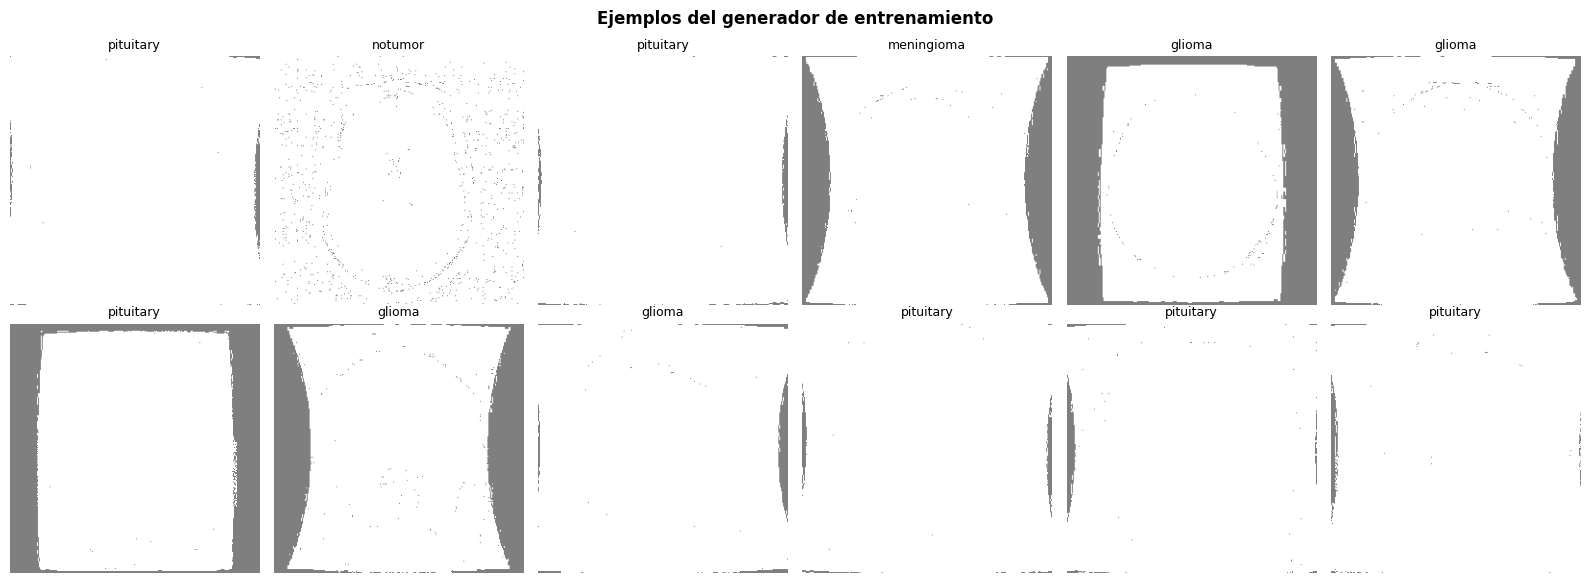

In [ ]:
# Funcion auxiliar para revertir el preprocesamiento de EfficientNet (visualizacion)
def deprocess_efficientnet(img):
    """Revierte preprocess_input: [-1, 1] -> [0, 1]."""
    return np.clip((img + 1.0) / 2.0, 0.0, 1.0)

# Mostrar ejemplos del generador de entrenamiento
sample_imgs, sample_labels = next(train_generator)

n_show = min(12, len(sample_imgs))
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle("Ejemplos del generador de entrenamiento",
             fontsize=12, fontweight="bold")

for i, ax in enumerate(axes.flat):
    if i >= n_show:
        ax.axis("off")
        continue
    ax.imshow(deprocess_efficientnet(sample_imgs[i]))
    ax.set_title(CLASS_NAMES[np.argmax(sample_labels[i])], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Construccion del modelo



In [ ]:
def construir_modelo(num_classes, img_size, dropout_1=0.40, dropout_2=0.30, l2_reg=1e-4):
    base = EfficientNetB4(
        weights     = "imagenet",
        include_top = False,
        input_shape = (img_size, img_size, 3)
    )
    base.trainable = False   

    inputs = keras.Input(shape=(img_size, img_size, 3))

    x = base(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.BatchNormalization()(x)
    x = layers.Dense(
        512, activation="relu",
        kernel_regularizer=regularizers.l2(l2_reg)
    )(x)
    x = layers.Dropout(dropout_1)(x)

    x = layers.BatchNormalization()(x)
    x = layers.Dense(
        256, activation="relu",
        kernel_regularizer=regularizers.l2(l2_reg)
    )(x)
    x = layers.Dropout(dropout_2)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs)
    return model, base


model, base_model = construir_modelo(
    num_classes = NUM_CLASSES,
    img_size    = IMG_SIZE,
    dropout_1   = DROPOUT_1,
    dropout_2   = DROPOUT_2,
    l2_reg      = L2_REG
)

total_params    = model.count_params()
trainable_params = sum(tf.size(w).numpy() for w in model.trainable_weights)
frozen_params   = total_params - trainable_params

print(f"Parametros totales     : {total_params:,}")
print(f"Parametros entrenables : {trainable_params:,}  ({100*trainable_params/total_params:.1f}%)")
print(f"Parametros congelados  : {frozen_params:,}  ({100*frozen_params/total_params:.1f}%)")

Parametros totales     : 18,733,411
Parametros entrenables : 1,054,980  (5.6%)
Parametros congelados  : 17,678,431  (94.4%)


In [ ]:
model.compile(
    optimizer = Adam(learning_rate=LR),
    loss      = CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics   = [
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ],
)

callbacks = [
    EarlyStopping(
        monitor              = "val_loss",
        patience             = 6,
        restore_best_weights = True,
        verbose              = 1
    ),
    ReduceLROnPlateau(
        monitor  = "val_loss",
        factor   = 0.3,
        patience = 3,
        min_lr   = 1e-7,
        verbose  = 1
    ),
    ModelCheckpoint(
        filepath       = CKPT_MODEL,
        monitor        = "val_loss",
        save_best_only = True,
        verbose        = 1
    )
]

print("Iniciando entrenamiento base (feature extraction)")
print(f"Base EfficientNetB4 congelada | LR={LR} | Epocas max={EPOCHS}\n")

history = model.fit(
    train_generator,
    validation_data = val_generator,
    epochs          = EPOCHS,
    callbacks       = callbacks,
    verbose         = 1
)

epochs_run   = len(history.history["loss"])
best_val_acc = max(history.history["val_accuracy"])
model_final  = model
print(f"\nEntrenamiento completado. Epocas: {epochs_run} | Mejor val_accuracy: {best_val_acc:.4f}")

Iniciando entrenamiento base (feature extraction)
Base EfficientNetB4 congelada | LR=0.0002 | Epocas max=100

Epoch 1/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.6573 - auc: 0.8616 - loss: 1.0729 - precision: 0.7042 - recall: 0.5897
Epoch 1: val_loss improved from None to 0.74840, saving model to /content/brain_tumor_project/models/ckpt_base.keras

Epoch 1: finished saving model to /content/brain_tumor_project/models/ckpt_base.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 92s 296ms/step - accuracy: 0.7560 - auc: 0.9300 - loss: 0.8707 - precision: 0.7930 - recall: 0.7089 - val_accuracy: 0.8536 - val_auc: 0.9743 - val_loss: 0.7484 - val_precision: 0.9373 - val_recall: 0.6946 - learning_rate: 2.0000e-04
Epoch 2/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.8482 - auc: 0.9720 - loss: 0.6651 - precision: 0.8754 - recall: 0.8266
Epoch 2: val_loss improved from 0.74840 to 0.55074, saving model to /content/brain_tumor_project/models/ckpt_base.keras

Epoch 2: finished savin

---
## Curvas de entrenamiento

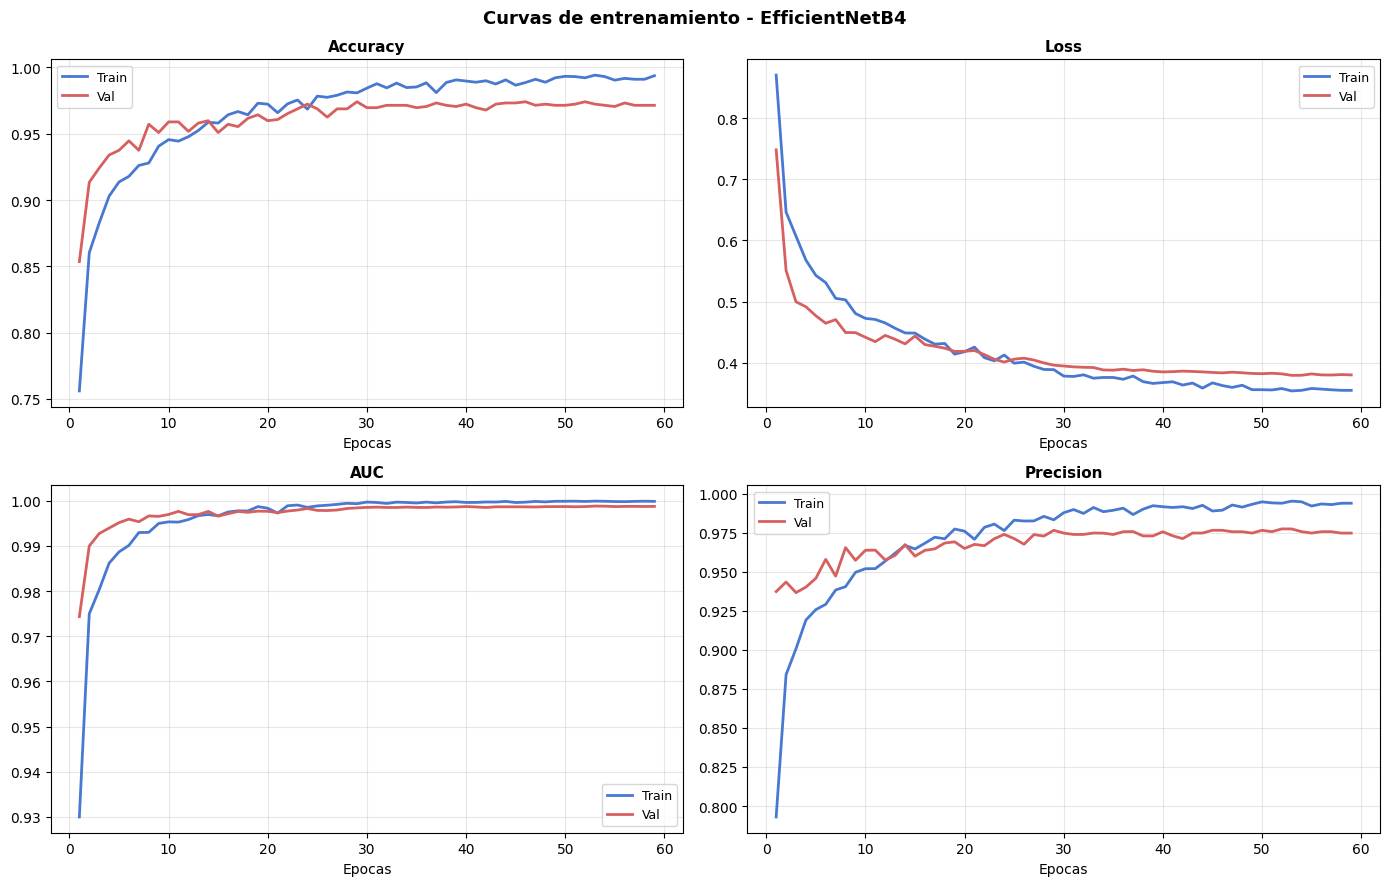

In [78]:
metricas_plot = [
    ("accuracy",  "val_accuracy",  "Accuracy"),
    ("loss",      "val_loss",      "Loss"),
    ("auc",       "val_auc",       "AUC"),
    ("precision", "val_precision", "Precision"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Curvas de entrenamiento - EfficientNetB4",
             fontsize=13, fontweight="bold")

for ax, (train_k, val_k, titulo) in zip(axes.flat, metricas_plot):
    epocas = range(1, len(history.history[train_k]) + 1)
    ax.plot(epocas, history.history[train_k], label="Train",
            color="#4878CF", linewidth=2)
    ax.plot(epocas, history.history[val_k],   label="Val",
            color="#D65F5F", linewidth=2)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel("Epocas")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Evaluacion sobre el conjunto de test


In [79]:
# Obtener predicciones sobre todo el set de test
test_generator.reset()
y_pred_proba = model_final.predict(test_generator, verbose=1)
y_pred       = np.argmax(y_pred_proba, axis=1)
y_true       = test_generator.classes

print(f"\nTotal predicciones : {len(y_pred)}")
print(f"Accuracy  : {np.mean(y_pred == y_true):.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step

Total predicciones : 1600
Accuracy  : 0.9344


---
## Matriz de confusion y reporte de clasificacion

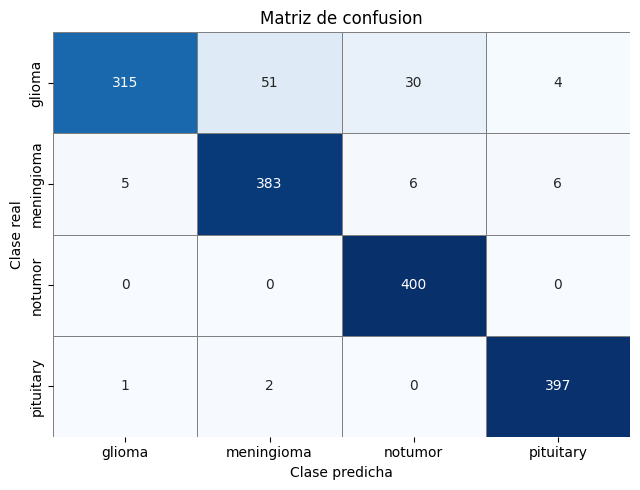

              precision    recall  f1-score   support

      glioma       0.98      0.79      0.87       400
  meningioma       0.88      0.96      0.92       400
     notumor       0.92      1.00      0.96       400
   pituitary       0.98      0.99      0.98       400

    accuracy                           0.93      1600
   macro avg       0.94      0.93      0.93      1600
weighted avg       0.94      0.93      0.93      1600



In [80]:
# Matriz de confusion
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)

plt.figure(figsize=(6.5, 5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False,
            linewidths=0.5, linecolor="gray")
plt.title("Matriz de confusion")
plt.ylabel("Clase real")
plt.xlabel("Clase predicha")
plt.tight_layout()
plt.show()

# Reporte de clasificacion
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

---
## Curvas ROC 

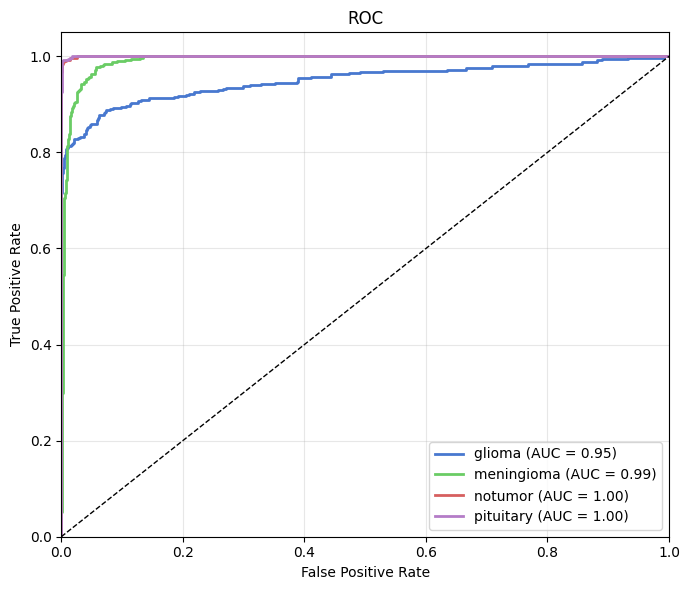

In [81]:
# Curvas ROC
n_classes = len(CLASS_NAMES)
y_true_bin = label_binarize(y_true, classes=range(n_classes))
y_scores = y_pred_proba

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(7, 6))
colors = ["#4878CF", "#6ACC65", "#D65F5F", "#B47CC7"]
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f"{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Visualizacion de predicciones

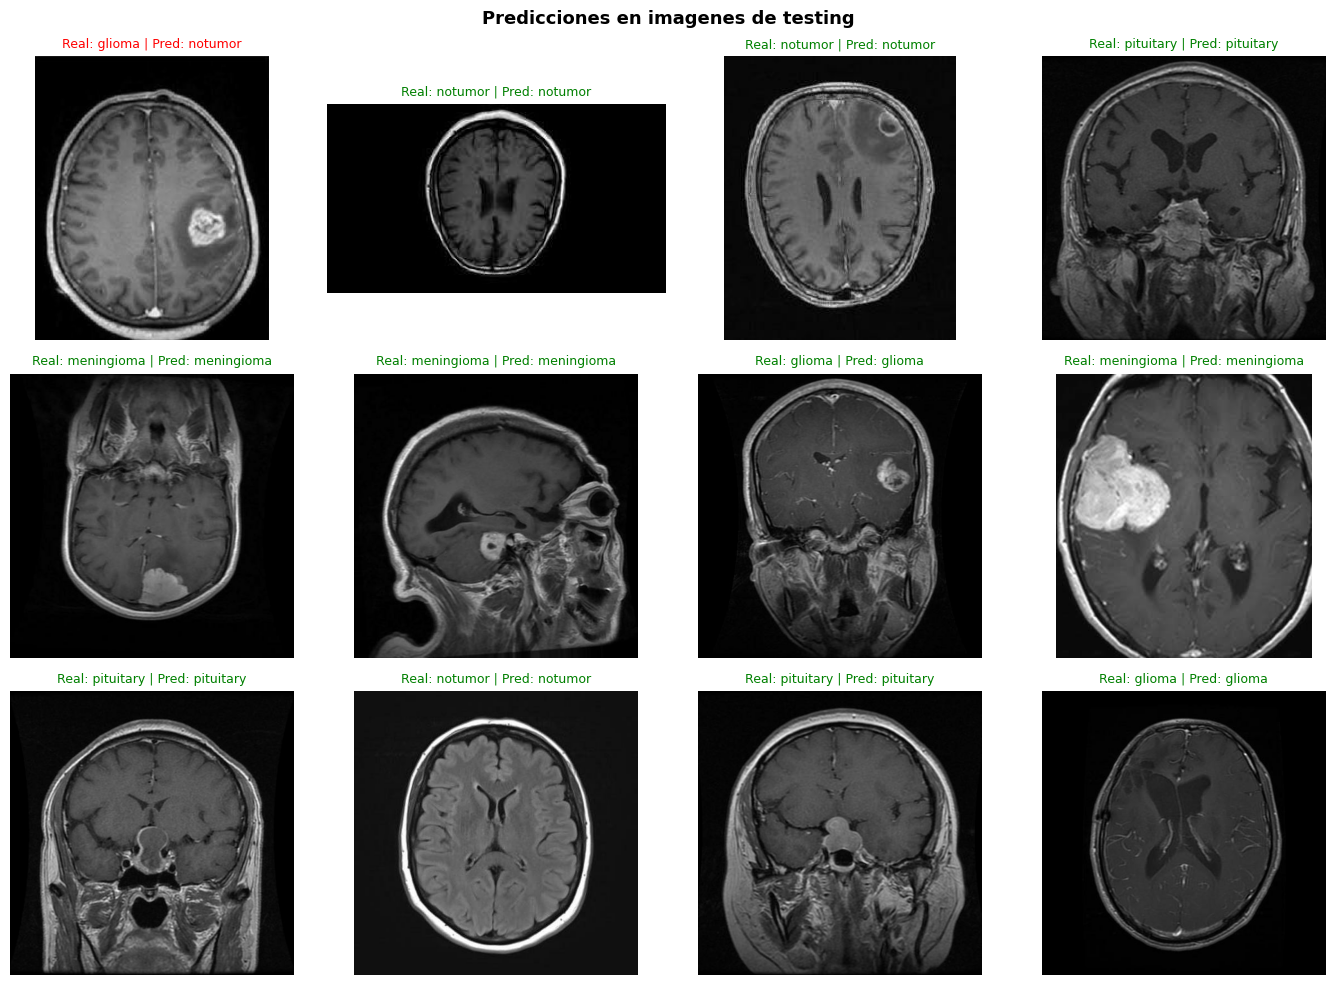

In [82]:
# Visualizar predicciones sobre imagenes del set de testing
n_mostrar = 12
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("Predicciones en imagenes de testing", fontsize=13, fontweight="bold")

test_images = []
test_labels = []
test_paths  = []

for clase in CLASS_NAMES:
    class_dir = TEST_DIR / clase
    imgs = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTENSIONS]
    random.shuffle(imgs)
    test_paths.extend(imgs[:3])  # 3 imagenes por clase

random.shuffle(test_paths)
test_paths = test_paths[:n_mostrar]

for i, img_path in enumerate(test_paths):
    img_bytes = tf.io.read_file(str(img_path))
    img = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.uint8)
    original = img.numpy()
    img_resized = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img_input = preprocess_input(tf.cast(img_resized, tf.float32))
    pred = model.predict(tf.expand_dims(img_input, 0), verbose=0)
    pred_class = CLASS_NAMES[np.argmax(pred)]
    true_class = img_path.parent.name
    correcto = pred_class == true_class
    title_color = "green" if correcto else "red"

    ax = axes.flat[i]
    ax.imshow(original)
    ax.set_title(
        f"Real: {true_class} | Pred: {pred_class}", fontsize=9, color=title_color
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Guardar el modelo final 

In [83]:
model_final.save(MODEL_FINAL)
print(f"Modelo final guardado en: {MODEL_FINAL}")

Modelo final guardado en: /content/drive/MyDrive/BrainTumorModel/brain_tumor_efficientnetb4_final.keras


---
## Resumen 

In [84]:
# Resumen basado en predicciones del set de test
test_acc = accuracy_score(y_true, y_pred)
test_prec, test_rec, test_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
  )
try:
    y_true_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
    test_auc = roc_auc_score(y_true_bin, y_pred_proba, average="macro", multi_class="ovr")
except ValueError:
    test_auc = float("nan")

print("=" * 55)
print("  RESUMEN DEL EXPERIMENTO")
print("=" * 55)
print(f"  Modelo base         : EfficientNetB4 (ImageNet)")
print(f"  Resolucion entrada  : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Label smoothing     : {LABEL_SMOOTH}")
print(f"  Dropout (1/2)       : {DROPOUT_1} / {DROPOUT_2}")
print()
print(f"  Split train         : {train_generator.samples} imagenes")
print(f"  Split val           : {val_generator.samples} imagenes")
print(f"  Split test          : {test_generator.samples} imagenes (Testing/ original)")
print()
print(f"  Epocas              : {epochs_run}")
print(f"  Mejor val_acc       : {best_val_acc:.4f}")
print()
print(f"  Test Accuracy       : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"  Test AUC (macro)    : {test_auc:.4f}")
print(f"  Test Precision      : {test_prec:.4f}")
print(f"  Test Recall         : {test_rec:.4f}")
print(f"  Test F1 (macro)     : {test_f1:.4f}")
print("=" * 55)

  RESUMEN DEL EXPERIMENTO
  Modelo base         : EfficientNetB4 (ImageNet)
  Resolucion entrada  : 260x260
  Label smoothing     : 0.05
  Dropout (1/2)       : 0.35 / 0.25

  Split train         : 4480 imagenes
  Split val           : 1120 imagenes
  Split test          : 1600 imagenes (Testing/ original)

  Epocas              : 59
  Mejor val_acc       : 0.9741

  Test Accuracy       : 0.9344  (93.44%)
  Test AUC (macro)    : 0.9852
  Test Precision      : 0.9382
  Test Recall         : 0.9344
  Test F1 (macro)     : 0.9327
